In [33]:
import requests
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import geopandas as gpd
from pathlib import Path
import geojson
from urllib.parse import urljoin

MAP_PATH = Path.cwd() / "maps"
MAP_PATH.mkdir(exist_ok=True, parents=True)


In [34]:
# WMS-Konfiguration
wms_url = "https://gis.tirol.gv.at/arcgis/services/Service_Public/terrain/MapServer/WMSServer"
layer_name = "Image_Schummerung_multi_DGM"

gdf = gpd.read_file("data/tirol_extent.geojson")

# Bounding Box aus GeoDataFrame
gdf = gdf.to_crs("EPSG:31287")
xmin, ymin, xmax, ymax = gdf.total_bounds

bbox = gdf.total_bounds

# WMS GetMap
params = {
    "SERVICE": "WMS",
    "VERSION": "1.1.1",
    "REQUEST": "GetMap",
    "LAYERS": layer_name,
    "STYLES": "",
    "SRS": "EPSG:31287",
    "BBOX": f"{xmin},{ymin},{xmax},{ymax}",
    "WIDTH": 2000,
    "HEIGHT": 2000,
    "FORMAT": "image/png",
    "TRANSPARENT": "TRUE"
}

response = requests.get(wms_url, params=params, timeout=60)
response.raise_for_status()

hillshade = Image.open(BytesIO(response.content))

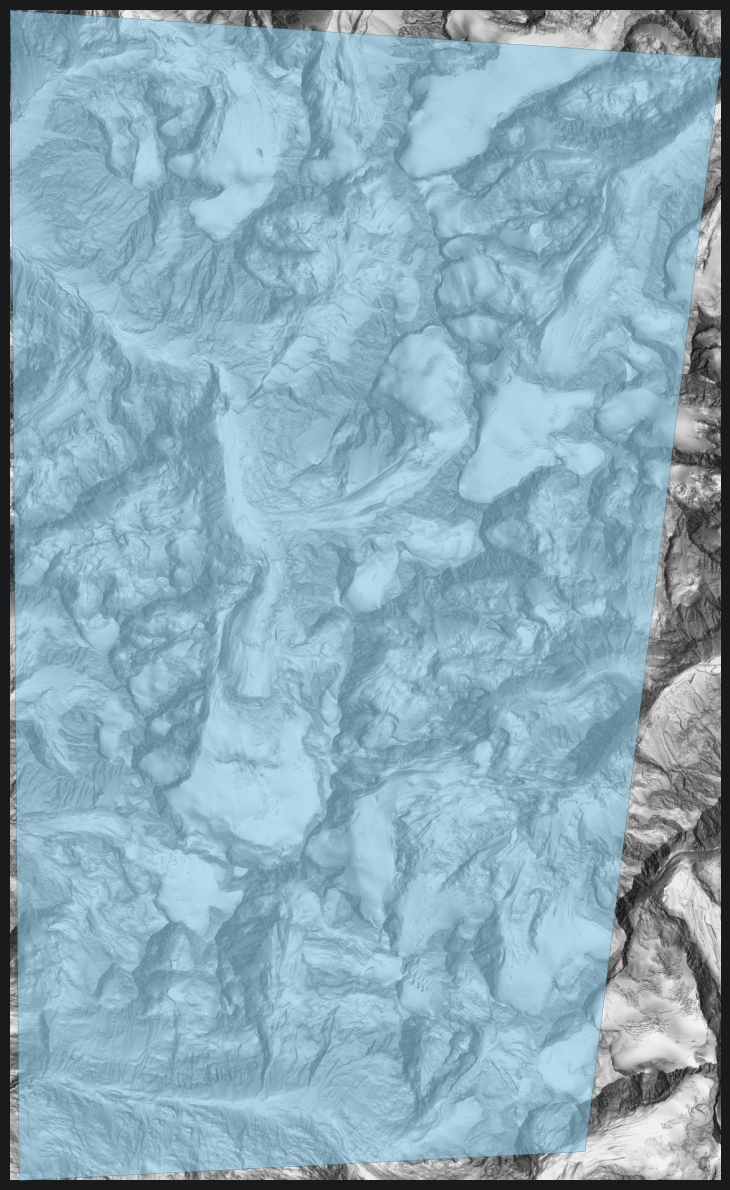

In [35]:
fig, ax = plt.subplots(figsize=(12, 12))

# Hillshade als Hintergrund
ax.imshow(
    hillshade,
    extent=[xmin, xmax, ymin, ymax],
    origin="upper",
    cmap="gray",
    zorder=0
)

# Polygone darüber
gdf.plot(
    ax=ax,
    facecolor="#8ECAE6",
    edgecolor="#126782",
    linewidth=0.3,
    alpha=0.6,
    zorder=1
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
def load_layer(collection_id: str, params={"limit": 1000}, verbose=True) -> gpd.GeoDataFrame:
    url = (
        "https://gis.lfrz.gv.at/api/geodata/i000901/"
        f"ogc/features/v1/collections/{collection_id}/items"
    )

    session = requests.Session()
    session.headers.update({
        "Accept": "application/geo+json"
    })

    features = []
    page = 0

    while url:
        response = session.get(
            url,
            params=params if page == 0 else None,
            timeout=60
        )
        response.raise_for_status()

        data = response.json()
        batch = data.get("features", [])
        features.extend(batch)

        page += 1
        if verbose:
            print(f"Seite {page}: {len(batch)} Features, gesamt {len(features)}")

        # Link zur nächsten Seite
        next_url = next(
            (
                link["href"]
                for link in data.get("links", [])
                if link.get("rel") == "next"
            ),
            None
        )

        url = urljoin(response.url, next_url) if next_url else None

    if features:
        gdf = gpd.GeoDataFrame.from_features(
            features,
            crs="EPSG:4326"
        )
        if verbose:
            print(f"Gesamt: {len(gdf)} Features")

        return gdf
    else:
        return None

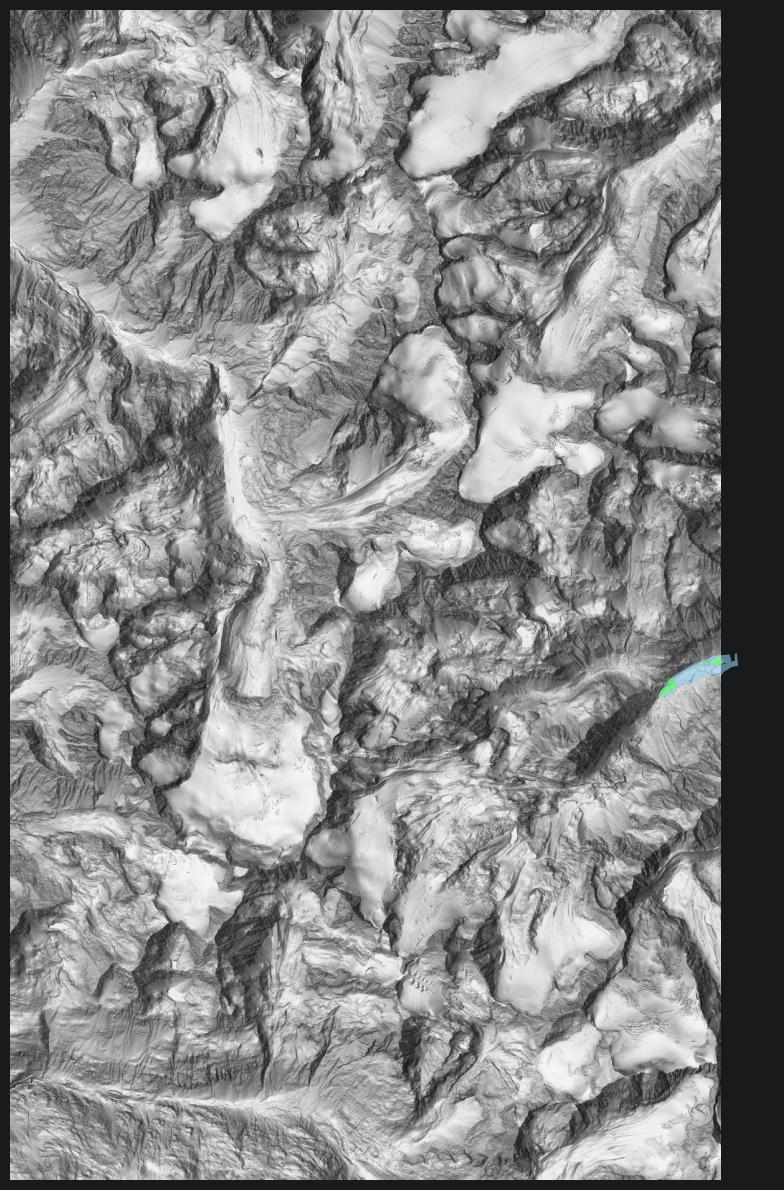

In [37]:
wfs_url = "https://gis.lfrz.gv.at/api/geodata/i000901/ogc/features/v1/"

bbox = ",".join(map(str, gdf.to_crs("EPSG:4326").total_bounds))
params = {
    "bbox": bbox,
    "limit": 1000
}

gdf_sz_la = load_layer("i000901:wlv_gzp_sz_la", params=params, verbose=False)
gdf_sz_wb = load_layer("i000901:wlv_gzp_sz_wb", params=params, verbose=False)

fig, ax = plt.subplots(figsize=(12, 12))

# Hillshade als Hintergrund
ax.imshow(
    hillshade,
    extent=[xmin, xmax, ymin, ymax],
    origin="upper",
    cmap="gray",
    zorder=0
)

gdf_sz_la.to_crs("EPSG:31287").plot(ax=ax, facecolor="#8ECAE6", edgecolor="none", alpha=0.6)
gdf_sz_wb.to_crs("EPSG:31287").plot(ax=ax, facecolor="#56fe54", edgecolor="none", alpha=0.6)

ax.set_axis_off()
plt.tight_layout()
